# Imports

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap
import numpy as np
import os
# from scipy.interpolate import make_interp_spline

# Paths

In [3]:
CSV_READ_DIR = '../../documents/tables/transfer_learning/'
IMAGES_SAVE_DIR = '../../documents/images/transfer_learning/'
os.makedirs(IMAGES_SAVE_DIR, exist_ok=True)

# General Functions

In [4]:
def pareto_front(df):
    points = df[["Accuracy", "Train Time"]].values
    pareto = []
    for i, (acc, time) in enumerate(points):
        dominated = False
        for j, (acc2, time2) in enumerate(points):
            if (acc2 >= acc and time2 <= time) and (acc2 > acc or time2 < time):
                dominated = True
                break
        if not dominated:
            pareto.append(i)
    return df.iloc[pareto]


In [5]:
# plot pareto fronts
def plot_pareto(df, title, linear_probe=True):
    plt.figure(figsize=(2.5, 2.5))
    # Scatter
    scatter_plot = sns.scatterplot(
        data=df,
        x="Train Time",
        y="Accuracy",
        hue="Model Name",
        style="Model Name",
        s=200
    )

    # remove gesture from pareto analysis
    df_temp = df[df['Model Name'] != 'Gesture from scratch']
    sorted_pareto_df = pareto_front(df_temp).sort_values("Train Time")

    plt.plot(
        sorted_pareto_df["Train Time"], 
        sorted_pareto_df["Accuracy"], 
        linestyle="--",     # solid line
        linewidth=1, 
        color="black", 
        alpha=1,          # transparency
        label="Pareto Front"
    )

    handles, labels = scatter_plot.get_legend_handles_labels()
    labels = [textwrap.fill(label, 20) for label in labels]

    plt.legend(
        handles,
        labels,
        frameon=False,
        bbox_to_anchor=(1.05, 1)
    )

    plt.xlabel('Training time in seconds')
    plt.ylabel('Accuracy (%)')
    # plt.title(title)
    img_save_name = f"{title.replace(':', '').replace(' ', '_').replace('-', '_')}.png"
    img_save_path = os.path.join(IMAGES_SAVE_DIR, img_save_name)
    plt.savefig(img_save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Main

In [6]:
# Read the CSV files
df_suturing = pd.read_csv(os.path.join(CSV_READ_DIR, 'df_suturing_tl.csv'))
df_needle_passing = pd.read_csv(os.path.join(CSV_READ_DIR, 'df_needle_tl.csv'))
df_knot_tying = pd.read_csv(os.path.join(CSV_READ_DIR, 'df_knot_tl.csv'))


# Convert accuracy to percentage
for df in [df_suturing, df_needle_passing, df_knot_tying]:
    df['Accuracy'] = (df['Accuracy'] * 100)

## All Pareto

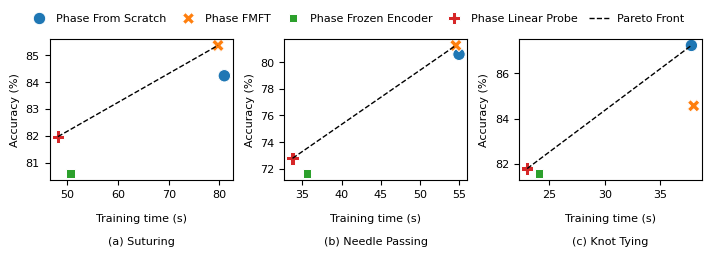

In [19]:
# Set font sizes for ACM format
plt.rcParams.update({
    'font.size': 8,
    'axes.labelsize': 8,
    'axes.titlesize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8
})

# Create a single figure with 3 subplots arranged horizontally
# ACM full pagewidth (double column) is ~7 inches
fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.5))

datasets = [
    (df_suturing.copy(), "(a) Suturing", axes[0]),
    (df_needle_passing.copy(), "(b) Needle Passing", axes[1]),
    (df_knot_tying.copy(), "(c) Knot Tying", axes[2])
]

handles_all = None
labels_all = None

for df, label, ax in datasets:
    # Scatter plot
    scatter_plot = sns.scatterplot(
        data=df,
        x="Train Time",
        y="Accuracy",
        hue="Model Name",
        style="Model Name",
        s=80,
        ax=ax,
        legend=False  # Temporarily disable legend
    )
    
    # Remove gesture from pareto analysis
    df_temp = df[df['Model Name'] != 'Gesture from scratch']
    sorted_pareto_df = pareto_front(df_temp).sort_values("Train Time")
    
    # Plot pareto front
    ax.plot(
        sorted_pareto_df["Train Time"], 
        sorted_pareto_df["Accuracy"], 
        linestyle="--",
        linewidth=1.0, 
        color="black", 
        alpha=1
    )
    
    # Set labels - place subplot label below x-axis label with extra padding
    ax.set_xlabel(f'Training time (s)\n\n{label}', fontsize=8, labelpad=10)
    ax.set_ylabel('Accuracy (%)', fontsize=8)
    
    # Get handles and labels from the first plot for the shared legend
    if handles_all is None:
        # Create a temporary legend to extract handles and labels
        temp_scatter = sns.scatterplot(
            data=df,
            x="Train Time",
            y="Accuracy",
            hue="Model Name",
            style="Model Name",
            s=80,
            ax=ax
        )
        handles_all, labels_all = ax.get_legend_handles_labels()
        
        # Transform labels to Camel Case and use FMFT for fine tuning
        labels_all = [
            label.replace('full model fine-tuning', 'FMFT')
            .replace('Phase from scratch', 'Phase From Scratch')
            .replace('Phase frozen encoder', 'Phase Frozen Encoder')
            .replace('Phase linear probe', 'Phase Linear Probe')
            for label in labels_all
        ]
        
        # Add Pareto Front to legend
        from matplotlib.lines import Line2D
        pareto_line = Line2D([0], [0], linestyle='--', linewidth=1.0, color='black', label='Pareto Front')
        handles_all.append(pareto_line)
        labels_all.append('Pareto Front')
        # Remove the temporary legend
        ax.get_legend().remove()

# Create a single legend on top, horizontally centered
# Reduced spacing between legend and plots
fig.legend(
    handles_all,
    labels_all,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=len(handles_all),
    frameon=False,
    fontsize=8,
    columnspacing=1.0,
    handletextpad=0.5
)

plt.tight_layout()
plt.subplots_adjust(top=0.88)

# Save the combined figure
img_save_path = os.path.join(IMAGES_SAVE_DIR, "Pareto_Front_Combined.png")
plt.savefig(img_save_path, dpi=300, bbox_inches='tight')
plt.show()

# Reset to default settings
plt.rcParams.update(plt.rcParamsDefault)